# Policy behavior

Inspect what saved policies choose in each region and local state. The action counts use several training seeds and all selected held-out demand seeds. The trajectory plots show one matched-demand example, so they are illustrative.

In [1]:
import json
import random
from collections import defaultdict

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from baselines import fixed_medium_action, random_action, threshold_action
from config import EnvironmentConfig, TrainingConfig
from environment import PollutionEnvironment
from run_followup import greedy_actions, load_agents

In [2]:
results_directory = "../results/followup/spillover_02"
policies = ("iql_local", "iql_global", "iql_mixed",
            "random", "fixed_medium", "threshold")
selected_training_seeds = (11, 23, 37, 41, 53)
example_training_seed = 11
example_demand_seed = 100000
state_detail_region = 0
example_policy = "iql_global"

with open(f"{results_directory}/manifest.json", encoding="utf-8") as file:
    manifest = json.load(file)

available_seeds = set(manifest["training"]["training_seeds"])
if not set(selected_training_seeds).issubset(available_seeds):
    raise ValueError("A selected training seed is missing from this scenario.")
if example_training_seed not in selected_training_seeds:
    raise ValueError("The example training seed must be selected above.")

evaluation_seeds = tuple(manifest["training"]["evaluation_seeds"])
if example_demand_seed not in evaluation_seeds:
    raise ValueError("The example demand seed must be one of the held-out seeds.")

environment_config = EnvironmentConfig()
environment_config.spillover = manifest["environment"]["spillover"]
settings = TrainingConfig()
print("Spillover:", environment_config.spillover)
print("Policies:", policies)

Spillover: 0.2
Policies: ('iql_local', 'iql_global', 'iql_mixed', 'random', 'fixed_medium', 'threshold')


## Re-evaluate actions on common demand seeds

The environment generates the same demand sequence for every policy. Random actions use a separate seeded generator. Learned agents act greedily.

In [3]:
policy_runs = []

for policy_name in policies:
    if policy_name.startswith("iql_"):
        mode = policy_name.removeprefix("iql_")
        if mode not in manifest["reward_modes"]:
            raise ValueError(f"Missing trained reward mode: {mode}")
        for seed in selected_training_seeds:
            agents = load_agents(f"{results_directory}/q_{mode}_{seed}.json", seed, settings)
            policy_runs.append((
                policy_name, seed,
                lambda observations, agents=agents: greedy_actions(observations, agents),
            ))
    elif policy_name == "random":
        for seed in selected_training_seeds:
            action_rng = random.Random(seed)
            policy_runs.append((
                policy_name, seed,
                lambda observations, rng=action_rng: tuple(
                    random_action(observation, rng) for observation in observations
                ),
            ))
    elif policy_name == "fixed_medium":
        policy_runs.append((
            policy_name, 0,
            lambda observations: tuple(fixed_medium_action(o) for o in observations),
        ))
    elif policy_name == "threshold":
        policy_runs.append((
            policy_name, 0,
            lambda observations: tuple(threshold_action(o) for o in observations),
        ))
    else:
        raise ValueError(f"Unknown policy: {policy_name}")

action_counts = defaultdict(int)
trajectory_rows = []

for policy_name, training_seed, policy in policy_runs:
    environment = PollutionEnvironment(config=environment_config)
    for demand_seed in evaluation_seeds:
        observations = environment.reset(demand_seed)
        for step in range(environment_config.episode_steps):
            current_demand = environment.demand
            actions = policy(observations)
            next_observations, _, _, info = environment.step(actions)

            for region in range(4):
                demand, pollution_bin = observations[region]
                action = actions[region]
                action_counts[(policy_name, region, demand, pollution_bin, action)] += 1
                if demand_seed == example_demand_seed and training_seed in (0, example_training_seed):
                    trajectory_rows.append({
                        "policy": policy_name, "training_seed": training_seed,
                        "step": step + 1, "region": region, "demand": current_demand[region],
                        "pollution_bin": pollution_bin, "action": action,
                        "emissions": info["emissions"][region],
                        "pollution_load": info["pollution_loads"][region],
                        "mitigation_cost": info["mitigation_costs"][region],
                    })
            observations = next_observations

count_rows = [
    {"policy": policy, "region": region, "demand": demand,
     "pollution_bin": pollution_bin, "action": action, "count": count}
    for (policy, region, demand, pollution_bin, action), count in action_counts.items()
]
counts = pd.DataFrame(count_rows)
trajectory = pd.DataFrame(trajectory_rows)
print(f"Recorded {counts['count'].sum():,} region-actions and {len(trajectory)} example region-steps.")

Recorded 88,000 region-actions and 1200 example region-steps.


## Action choices by region

Each bar sums to one within its policy and region. Policies with different numbers of training seeds are therefore comparable as action fractions.

action                   0      1      2
policy       region                     
fixed_medium 0       0.000  1.000  0.000
             1       0.000  1.000  0.000
             2       0.000  1.000  0.000
             3       0.000  1.000  0.000
iql_global   0       0.423  0.434  0.143
             1       0.344  0.401  0.255
             2       0.432  0.417  0.151
             3       0.463  0.416  0.120
iql_local    0       0.497  0.364  0.139
             1       0.629  0.301  0.070
             2       0.709  0.139  0.152
             3       0.553  0.325  0.122
iql_mixed    0       0.642  0.249  0.109
             1       0.604  0.305  0.091
             2       0.529  0.401  0.070
             3       0.435  0.480  0.085
random       0       0.332  0.326  0.342
             1       0.333  0.338  0.329
             2       0.336  0.333  0.330
             3       0.341  0.338  0.321
threshold    0       0.463  0.536  0.001
             1       0.446  0.549  0.005
             2       0.464  0.529  0.007
             3       0.394  0.598  0.008

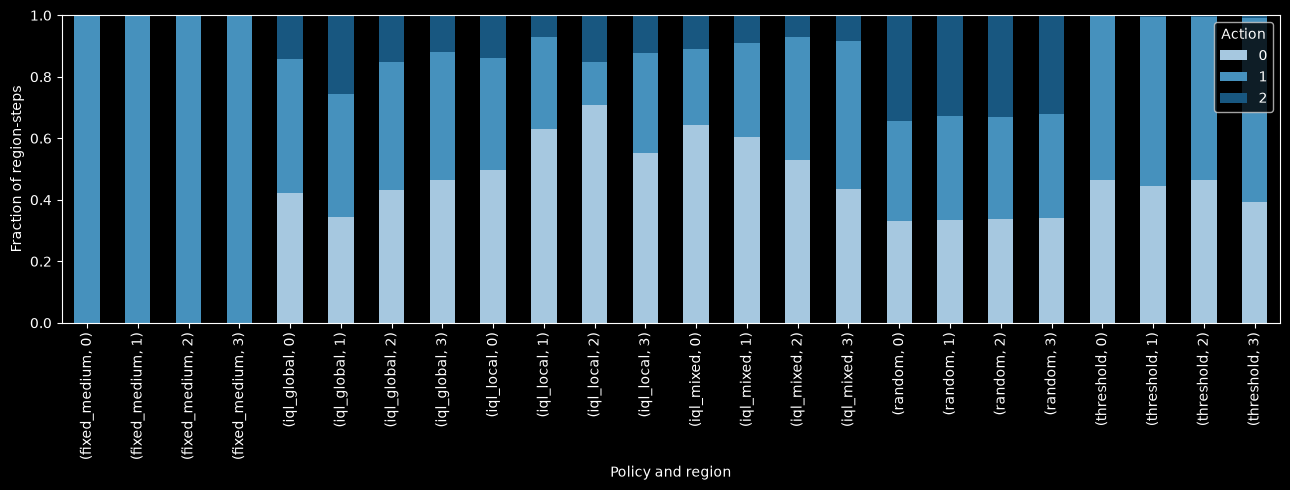

In [4]:
regional_actions = (counts.groupby(["policy", "region", "action"])["count"]
                    .sum().unstack(fill_value=0))
regional_fractions = regional_actions.div(regional_actions.sum(axis=1), axis=0)
display(regional_fractions.round(3))

regional_fractions.plot(kind="bar", stacked=True, figsize=(13, 5),
                        color=["#a6c8e0", "#4691bd", "#185780"])
plt.ylabel("Fraction of region-steps")
plt.xlabel("Policy and region")
plt.legend(title="Action")
plt.tight_layout()
plt.show()

## Local-state detail

In [5]:
region_counts = counts[counts["region"] == state_detail_region]
state_actions = (region_counts.groupby(["policy", "demand", "pollution_bin", "action"])["count"]
                 .sum().unstack(fill_value=0))
state_fractions = state_actions.div(state_actions.sum(axis=1), axis=0)
display(state_fractions.round(3))

action                                 0      1      2
policy       demand pollution_bin                     
fixed_medium 0      0              0.000  1.000  0.000
                    1              0.000  1.000  0.000
                    2              0.000  1.000  0.000
             1      0              0.000  1.000  0.000
                    1              0.000  1.000  0.000
                    2              0.000  1.000  0.000
             2      1              0.000  1.000  0.000
                    2              0.000  1.000  0.000
iql_global   0      0              0.762  0.238  0.000
                    1              0.607  0.393  0.000
                    2              0.237  0.156  0.607
             1      0              0.438  0.000  0.562
                    1              0.585  0.415  0.000
                    2              0.594  0.406  0.000
             2      1              0.558  0.442  0.000
                    2              0.000  0.610  0.390
                    3              0.000  0.000  1.000
iql_local    0      0              1.000  0.000  0.000
                    1              0.803  0.197  0.000
                    2              1.000  0.000  0.000
             1      0              0.000  0.000  1.000
                    1              0.365  0.442  0.193
                    2              0.581  0.419  0.000
                    3              0.000  0.030  0.970
             2      0              0.000  1.000  0.000
                    1              0.000  0.446  0.554
                    2              0.215  0.642  0.143
                    3              0.000  0.000  1.000
iql_mixed    0      1              1.000  0.000  0.000
                    2              1.000  0.000  0.000
             1      1              0.791  0.209  0.000
                    2              0.819  0.181  0.000
                    3              0.000  1.000  0.000
             2      1              0.340  0.660  0.000
                    2              0.000  0.581  0.419
                    3              0.000  0.000  1.000
random       0      0              0.351  0.394  0.255
                    1              0.316  0.325  0.360
                    2              0.318  0.356  0.325
                    3              0.500  0.000  0.500
             1      0              0.310  0.366  0.324
                    1              0.358  0.311  0.331
                    2              0.347  0.319  0.334
                    3              0.294  0.353  0.353
             2      0              0.200  0.800  0.000
                    1              0.335  0.324  0.342
                    2              0.327  0.330  0.343
                    3              0.269  0.192  0.538
threshold    0      1              1.000  0.000  0.000
                    2              0.000  1.000  0.000
             1      1              1.000  0.000  0.000
                    2              0.000  1.000  0.000
                    3              0.000  0.000  1.000
             2      1              1.000  0.000  0.000
                    2              0.000  1.000  0.000

## Matched-demand trajectory

The mean plot averages the four regions within the example episode. The second plot shows each region for the selected example policy.

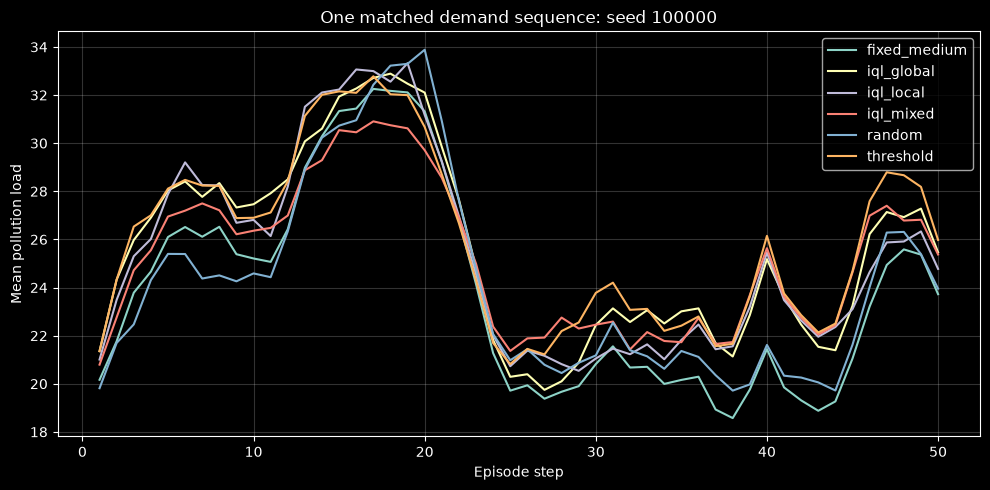

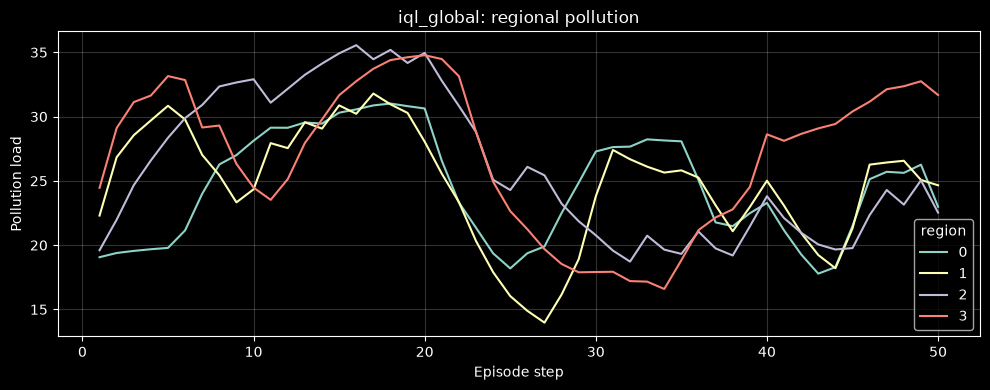

In [6]:
mean_trajectory = (trajectory.groupby(["policy", "step"])["pollution_load"]
                   .mean().reset_index())
figure, axis = plt.subplots(figsize=(10, 5))
for policy_name, rows in mean_trajectory.groupby("policy"):
    axis.plot(rows["step"], rows["pollution_load"], label=policy_name)
axis.set(xlabel="Episode step", ylabel="Mean pollution load",
         title=f"One matched demand sequence: seed {example_demand_seed}")
axis.legend()
axis.grid(alpha=0.2)
figure.tight_layout()
plt.show()

region_trajectory = trajectory[trajectory["policy"] == example_policy]
if region_trajectory.empty:
    raise ValueError("Choose an example_policy included in policies.")
regional_loads = region_trajectory.pivot(index="step", columns="region", values="pollution_load")
regional_loads.plot(figsize=(10, 4), title=f"{example_policy}: regional pollution")
plt.xlabel("Episode step")
plt.ylabel("Pollution load")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [7]:
save_behavior = False
behavior_output_directory = "../results/notebook_runs/policy_behavior_01"

if save_behavior:
    record = {
        "source_scenario": results_directory, "policies": list(policies),
        "training_seeds": list(selected_training_seeds),
        "evaluation_seeds": list(evaluation_seeds),
        "example_training_seed": example_training_seed,
        "example_demand_seed": example_demand_seed,
    }
    with open(f"{behavior_output_directory}/manifest.json", "x", encoding="utf-8") as file:
        json.dump(record, file, indent=2)
        file.write("\n")
    counts.to_csv(f"{behavior_output_directory}/action_counts_by_state.csv", index=False)
    trajectory.to_csv(f"{behavior_output_directory}/matched_trajectory.csv", index=False)
    print(f"Saved diagnostic record to {behavior_output_directory}")

## Reading the completed behavior diagnostic

Across the original five trained seeds at spillover **0.2**, global-reward agents chose low mitigation (action 0) in **42%** of region-steps and high mitigation (action 2) in **17%**. Local-reward agents chose them in **60%** and **12%**, respectively. That shift toward more mitigation is consistent with the global policy's lower average pollution and higher cost in the larger 20-seed outcome study. The five-seed action counts and 20-seed outcome means are different summaries, so the percentages should not be treated as one joint estimate.

The regional bars reveal variation that the overall fraction hides. In region 1, the global agents chose high mitigation in about **25%** of steps, while local agents did so in about **7%**. The state table helps locate where choices differ, but policies visit different states at different rates, and rare bins can give unstable fractions. These patterns describe the saved agents; they do not establish why a particular region learned a choice.

The example demand seed **100000** is a useful caution: global-reward Q-learning averaged **25.58** pollution in that one episode, slightly above local-reward Q-learning's **25.34**, even though the global policy had lower pollution across the full evaluation.